# Ma trận nhầm lẫn

*Bài 4, mục 4.1.5.* Mô hình thi đỗ $P(\text{đỗ}) = \sigma(1.5046\,x - 4.0777)$ với ngưỡng $\tau = 0.3$ (với ngưỡng 0.5 ma trận đối xứng, TN = TP = 8 và FP = FN = 2, nên mọi chỉ số đều bằng 0.8, khó phân biệt). Quy ước giống scikit-learn: **hàng là nhãn thật, cột là nhãn dự đoán**, lớp 0 đứng trước:

| | Dự đoán 0 | Dự đoán 1 |
|---|---|---|
| **Thật 0** | TN | FP |
| **Thật 1** | FN | TP |

In [1]:
import numpy as np
from sklearn.metrics import confusion_matrix

X = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
              2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50])
y = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])
w0, w1 = -4.0777, 1.5046                      # nghiệm tìm được ở notebook 02

p = 1 / (1 + np.exp(-(w0 + w1 * X)))          # xác suất thi đỗ
threshold = 0.3                               # ngưỡng phân loại τ
y_pred = (p >= threshold).astype(int)         # dự đoán đỗ khi số giờ >= 2.25

## 1. Phân loại từng mẫu thành TP, TN, FP, FN

In [2]:
for hours, actual, predicted in zip(X, y, y_pred):
    outcome = {(1, 1): 'TP', (0, 0): 'TN', (0, 1): 'FP', (1, 0): 'FN'}[(actual, predicted)]
    print('%.2f giờ: thật = %d, dự đoán = %d -> %s' % (hours, actual, predicted, outcome))

0.50 giờ: thật = 0, dự đoán = 0 -> TN
0.75 giờ: thật = 0, dự đoán = 0 -> TN
1.00 giờ: thật = 0, dự đoán = 0 -> TN
1.25 giờ: thật = 0, dự đoán = 0 -> TN
1.50 giờ: thật = 0, dự đoán = 0 -> TN
1.75 giờ: thật = 0, dự đoán = 0 -> TN
1.75 giờ: thật = 1, dự đoán = 0 -> FN
2.00 giờ: thật = 0, dự đoán = 0 -> TN
2.25 giờ: thật = 1, dự đoán = 1 -> TP
2.50 giờ: thật = 0, dự đoán = 1 -> FP
2.75 giờ: thật = 1, dự đoán = 1 -> TP
3.00 giờ: thật = 0, dự đoán = 1 -> FP
3.25 giờ: thật = 1, dự đoán = 1 -> TP
3.50 giờ: thật = 0, dự đoán = 1 -> FP
4.00 giờ: thật = 1, dự đoán = 1 -> TP
4.25 giờ: thật = 1, dự đoán = 1 -> TP
4.50 giờ: thật = 1, dự đoán = 1 -> TP
4.75 giờ: thật = 1, dự đoán = 1 -> TP
5.00 giờ: thật = 1, dự đoán = 1 -> TP
5.50 giờ: thật = 1, dự đoán = 1 -> TP


## 2. Ma trận nhầm lẫn

In [3]:
conf_matrix = confusion_matrix(y, y_pred)
print(conf_matrix)
tn, fp, fn, tp = conf_matrix.ravel()
print('TN = %d, FP = %d, FN = %d, TP = %d' % (tn, fp, fn, tp))

[[7 3]
 [1 9]]
TN = 7, FP = 3, FN = 1, TP = 9


### Ma trận nhầm lẫn chuẩn hóa

Ma trận trên đếm **số mẫu**. Khi hai lớp có số mẫu khác nhau, số đếm khó so sánh, nên ta chuẩn hóa thành **tỉ lệ** bằng tham số `normalize`:

- `normalize='true'`: chia mỗi hàng cho tổng hàng (số mẫu thật của lớp đó), mỗi hàng cộng lại bằng 1. Ô dưới phải là $\frac{TP}{TP+FN}$ (Recall), ô trên trái là $\frac{TN}{TN+FP}$ (độ đặc hiệu).
- `normalize='pred'`: chia mỗi cột cho tổng cột (số mẫu được dự đoán vào lớp đó), mỗi cột cộng lại bằng 1. Ô dưới phải là $\frac{TP}{TP+FP}$ (Precision).
- `normalize='all'`: chia mọi ô cho tổng số mẫu, cả ma trận cộng lại bằng 1; tổng đường chéo là Accuracy.

In [4]:
np.set_printoptions(precision=3, suppress=True)  # in 3 chữ số thập phân

for mode in ['true', 'pred', 'all']:
    normalized_matrix = confusion_matrix(y, y_pred, normalize=mode)  # ma trận nhầm lẫn chuẩn hóa
    print("normalize='%s':" % mode)
    print(normalized_matrix)
    print()

normalize='true':
[[0.7 0.3]
 [0.1 0.9]]

normalize='pred':
[[0.875 0.25 ]
 [0.125 0.75 ]]

normalize='all':
[[0.35 0.15]
 [0.05 0.45]]



Đọc kết quả với ngưỡng 0.3:

- `'true'`: 70% người thật sự trượt được dự đoán trượt (độ đặc hiệu = 7/10), 90% người thật sự đỗ được dự đoán đỗ (Recall = 9/10).
- `'pred'`: trong 12 người được dự đoán đỗ, 75% thật sự đỗ (Precision = 9/12); trong 8 người được dự đoán trượt, 87.5% thật sự trượt (7/8).
- `'all'`: tổng đường chéo 0.35 + 0.45 = 0.80 chính là Accuracy.

Hai cách chuẩn hóa `'true'` và `'pred'` cho hai ma trận khác nhau vì chúng chia theo hai mẫu số khác nhau: theo nhãn thật (hàng) hay theo nhãn dự đoán (cột).

## 3. Biểu diễn ma trận nhầm lẫn bằng đồ họa

`ConfusionMatrixDisplay` của scikit-learn vẽ ma trận thành một lưới ô màu: ô càng đậm thì càng nhiều mẫu. Đọc hình theo đúng quy ước trên: hàng là nhãn thật, cột là nhãn dự đoán. Đường chéo chính (TN, TP) là dự đoán đúng, hai ô còn lại (FP, FN) là dự đoán sai.

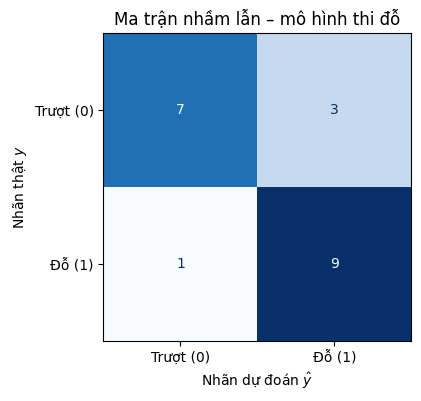

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ['Trượt (0)', 'Đỗ (1)']  # tên hiển thị của lớp 0 và lớp 1

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(conf_matrix, display_labels=class_names).plot(cmap='Blues', colorbar=False, ax=ax)
ax.set_xlabel(r'Nhãn dự đoán $\hat{y}$')
ax.set_ylabel('Nhãn thật $y$')
ax.set_title('Ma trận nhầm lẫn – mô hình thi đỗ')
plt.show()

Có thể vẽ thẳng từ nhãn thật và nhãn dự đoán bằng `from_predictions`, không cần tính ma trận trước. Tham số `normalize='true'` chia mỗi hàng cho tổng của hàng đó, nên mỗi ô là **tỉ lệ** trong số mẫu thật thuộc lớp đó. Ô dưới phải khi đó chính là Recall = TP / (TP + FN), ô trên trái là tỉ lệ người trượt được đoán đúng TN / (TN + FP). Dạng chuẩn hóa hữu ích khi hai lớp có số mẫu chênh lệch nhiều.

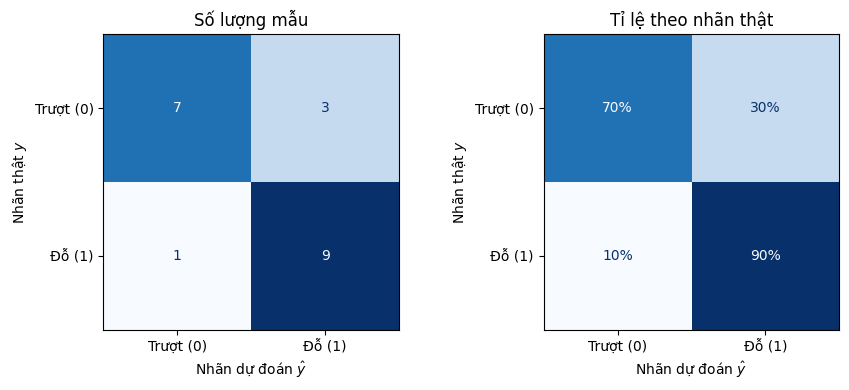

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

# Bên trái: số lượng mẫu; bên phải: tỉ lệ theo từng hàng (nhãn thật)
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=class_names,
                                        cmap='Blues', colorbar=False, ax=axes[0])
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=class_names, normalize='true',
                                        values_format='.0%', cmap='Blues', colorbar=False, ax=axes[1])

axes[0].set_title('Số lượng mẫu')
axes[1].set_title('Tỉ lệ theo nhãn thật')
for ax in axes:
    ax.set_xlabel(r'Nhãn dự đoán $\hat{y}$')
    ax.set_ylabel('Nhãn thật $y$')
plt.tight_layout()
plt.show()